<a href="https://colab.research.google.com/github/LGLV-Ciencia-de-Datos/Bioinformatics_DCA/blob/master/U4_Cuaderno3_Integracion_Bioinformatica_en_Seguridad_Alimentaria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

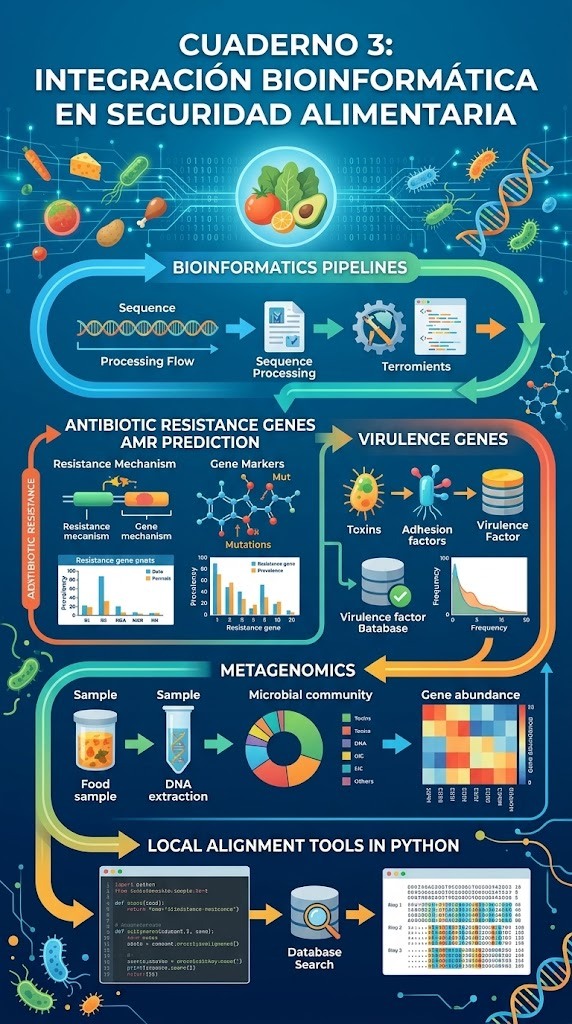

# Cuaderno 3: Integración Bioinformática en Seguridad Alimentaria

Este cuaderno interactivo ejecuta el flujo en **Python** para la integración bioinformática en **seguridad alimentaria**, abarcando la predicción de resistencia a antibióticos (**AMR**), identificación de **genes de virulencia**, análisis metagenómico de comunidades microbianas en muestras alimentarias y alineamiento local con algoritmos de búsqueda contra bases de datos especializadas (CARD / VFDB).

---

### Contenido del Cuaderno:
1. **Flujo de Procesamiento y Alineamiento Local en Python**:
   - Algoritmo de alineamiento local de secuencias (Smith-Waterman / BLAST local) para búsqueda en bases de datos de referencia (CARD / VFDB).
2. **Módulo AMR (Antibiotic Resistance Genes Prediction)**:
   - Frecuencia y prevalencia de genes de resistencia por mecanismo de acción (bombas de eflujo, inactivación enzimática, mutación de diana).
3. **Módulo de Genes de Virulencia (Virulence Factors)**:
   - Clasificación de factores de virulencia (toxinas, factores de adhesión, sistemas de secreción) y curva de frecuencia.
4. **Metagenómica de Alimentos y Abundancia Relativa**:
   - Composición de la comunidad microbiana (Gráfico de Dona / Rosca) desde la extracción de ADN alimentario.
   - Mapa de calor (*Heatmap*) de abundancia de genes de resistencia y virulencia entre muestras alimentarias.

## Paso 0: Importación de Librerías y Configuración

Cargamos las librerías científicas requeridas.

In [ ]:
# Si ejecutas en Google Colab o Jupyter local, puedes descomentar para instalar:
# !pip install numpy pandas matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Librerías para Seguridad Alimentaria cargadas exitosamente.")

## Paso 1: Algoritmo de Alineamiento Local en Python (Smith-Waterman / BLAST Local)

Implementamos una función en Python para simular la búsqueda de alineamiento local de lecturas de metagenoma alimentario contra una base de datos de genes de resistencia (CARD) o virulencia (VFDB).

In [ ]:
def local_alignment_score(seq1, seq2, match=2, mismatch=-1, gap=-2):
    """Algoritmo de alineamiento local estilo Smith-Waterman."""
    m, n = len(seq1), len(seq2)
    score_matrix = np.zeros((m + 1, n + 1), dtype=int)
    max_score = 0

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if seq1[i-1] == seq2[j-1]:
                diag = score_matrix[i-1][j-1] + match
            else:
                diag = score_matrix[i-1][j-1] + mismatch
            up = score_matrix[i-1][j] + gap
            left = score_matrix[i][j-1] + gap
            score_matrix[i][j] = max(0, diag, up, left)
            if score_matrix[i][j] > max_score:
                max_score = score_matrix[i][j]
    return max_score

# Secuencias de prueba (lectura metagenómica vs referencia de gen ermB / blaTEM)
read = "ATGGCGAACCGGTTACGAATGCCGT"
ref_gene = "ATGGCGAACCGGTTACGAATGCCGTTACGAAGGCT"

score = local_alignment_score(read, ref_gene)
identity = (score / (len(read) * 2)) * 100
print(f"--- RESULTADO DE BÚSQUEDA EN BASE DE DATOS LOCAL ---")
print(f"Puntaje de Alineamiento Local: {score}")
print(f"Porcentaje de Identidad Estimado: {identity:.2f}%")

## Paso 2: Predicción de Genes de Resistencia a Antibióticos (AMR)

Representamos la prevalencia y distribución de genes de resistencia en las muestras alimentarias por mecanismo de acción (Beta-lactámicos, Tetraciclinas, Aminoglucósidos, Bombas de Eflujo).

In [ ]:
# Datos de genes AMR detectados
amr_data = {
    'Gene_Marker': ['blaTEM', 'tet(M)', "aph(3')", 'erm(B)', 'sul1', 'mcr-1', 'qnrS'],
    'Mecanismo': ['Inactivación Enzimática', 'Protección Ribosomal', 'Inactivación Enzimática',
                  'Modificación de Target', 'Inhibición de Vía', 'Modificación de Carga', 'Protección de Target'],
    'Prevalencia_%': [85.4, 68.2, 45.0, 52.3, 38.9, 12.5, 24.1]
}

amr_df = pd.DataFrame(amr_data)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(amr_df['Gene_Marker'], amr_df['Prevalencia_%'], color='#d95f02', edgecolor='black', alpha=0.85)

ax.set_title("PREVALENCIA DE GENES DE RESISTENCIA A ANTIBIÓTICOS (AMR)\nen Aislados de Origen Alimentario", fontsize=13, fontweight='bold')
ax.set_xlabel("Marcador Génico de Resistencia", fontsize=11)
ax.set_ylabel("Prevalencia (%)", fontsize=11)
ax.set_ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1.5, f"{height:.1f}%", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Datos de genes AMR detectados
amr_data = {
    'Gene_Marker': ['blaTEM', 'tet(M)', "aph(3')", 'erm(B)', 'sul1', 'mcr-1', 'qnrS'],
    'Mecanismo': ['Inactivación Enzimática', 'Protección Ribosomal', 'Inactivación Enzimática',
                  'Modificación de Target', 'Inhibición de Vía', 'Modificación de Carga', 'Protección de Target'],
    'Prevalencia_%': [85.4, 68.2, 45.0, 52.3, 38.9, 12.5, 24.1]
}

amr_df = pd.DataFrame(amr_data)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(amr_df['Gene_Marker'], amr_df['Prevalencia_%'], color='#160842', edgecolor='black', alpha=0.85)

ax.set_title("PREVALENCIA DE GENES DE RESISTENCIA A ANTIBIÓTICOS (AMR)\nen Aislados de Origen Alimentario", fontsize=13, fontweight='bold')
ax.set_xlabel("Marcador Génico de Resistencia", fontsize=11)
ax.set_ylabel("Prevalencia (%)", fontsize=11)
ax.set_ylim(0, 100)

# Agregar etiquetas en las barras
for i, bar in enumerate(bars):
    height = bar.get_height()
    mecanismo = amr_df['Mecanismo'].iloc[i]

    # Porcentaje arriba de la barra
    ax.text(bar.get_x() + bar.get_width()/2., height + 1.5, f"{height:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

    # Mecanismo en el cuerpo de la barra (centrado verticalmente dentro de la barra)
    # Rotamos el texto verticalmente para asegurar que quepa bien dentro de la barra
    ax.text(bar.get_x() + bar.get_width()/2., height / 2., mecanismo,
            ha='center', va='center', color='yellow', fontsize=8.5, fontweight='bold', rotation=90)

plt.tight_layout()
plt.show()

***Gráfico de Barras de Prevalencia de Genes de Resistencia (AMR)***

¿Qué representa?
- Muestra el porcentaje de detección y prevalencia de marcadores genéticos de resistencia a antibióticos específicos (como blaTEM, tet(M), erm(B), etc.) en los aislados microbianos recuperados de las muestras alimentarias.

Cómo interpretarlo:

- Permite identificar los mecanismos de resistencia predominantes en la cadena alimentaria (por ejemplo, altos valores en blaTEM señalan resistencia a beta-lactámicos por inactivación enzimática).

- Evalúa el riesgo de transferencia horizontal de resistencia hacia patógenos humanos y la microbiota intestinal del consumidor.

## Paso 3: Frecuencia de Factores de Virulencia (Virulence Factors Database - VFDB)

Generamos el gráfico de distribución de frecuencia para genes de virulencia asociados a patógenos alimentarios (toxinas, adehsinas, sistemas de secreción tipo III/IV).

In [ ]:
# Simulación de distribución de frecuencia de genes de virulencia
x_freq = np.linspace(1, 50, 200)
# Distribución log-normal / exponencial decreciente
y_freq = 100 * np.exp(-0.1 * x_freq)

plt.figure(figsize=(8, 5))
plt.plot(x_freq, y_freq, color='#7570b3', linewidth=2.5)
plt.fill_between(x_freq, y_freq, color='#7570b3', alpha=0.25)

plt.title("FRECUENCIA DE FACTORES DE VIRULENCIA (VFDB)\nToxinas, Adhesinas y Factores de Invasión", fontsize=13, fontweight='bold')
plt.xlabel("Número de Factores de Virulencia Detectados", fontsize=11)
plt.ylabel("Frecuencia Relativa (%)", fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# MEJORA: Distribución y Frecuencia de Factores de Virulencia (VFDB)
# ==============================================================================

# 1. Definición de categorías funcionales de virulencia reales (VFDB)
virulence_categories = {
    'Adhesinas / Fimbrias': 88.5,        # Detección en % de aislamientos
    'Sistemas de Secreción (T3SS/T4SS)': 74.2,
    'Sideróforos (Captación de Fe)': 65.0,
    'Toxinas / Enterotoxinas': 58.3,
    'Factores de Invasión Celular': 42.1,
    'Formación de Biofilm': 35.8,
    'Movilidad / Flagelos': 29.4
}

# Convertir a DataFrame ordenado de mayor a menor
vf_df = pd.DataFrame(
    list(virulence_categories.items()),
    columns=['Categoria_Virulencia', 'Frecuencia_%']
).sort_values('Frecuencia_%', ascending=True)

# 2. Visualización clara mediante gráfico de barras horizontales
plt.figure(figsize=(9, 5.5))
bars = plt.barh(
    vf_df['Categoria_Virulencia'],
    vf_df['Frecuencia_%'],
    color='#7570b3',
    edgecolor='black',
    alpha=0.85,
    height=0.6
)

# Añadir etiquetas con el valor numérico exacto en cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1.5,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='#2c3e50'
    )

plt.title("DETECCIÓN Y FRECUENCIA DE FACTORES DE VIRULENCIA (VFDB)\nCategorías Funcionales en Aislados de Alimentos", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Frecuencia Relativa de Detección (%)", fontsize=11)
plt.ylabel("Categoría Funcional (VFDB)", fontsize=11)
plt.xlim(0, 105) # Margen para las etiquetas
plt.tight_layout()
plt.show()

***Curva de Frecuencia de Factores de Virulencia (VFDB)***

¿Qué representa?
- La distribución de la frecuencia relativa de genes asociados a factores de virulencia (toxinas, factores de adhesión e invasión) en los microorganismos evaluados.

Cómo interpretarlo:

- Una mayor densidad acumulada de factores de virulencia indica que los patógenos presentes en el alimento poseen un alto potencial de patogenicidad y capacidad para desencadenar enfermedades graves transmitidas por alimentos (ETAs).

## Paso 4: Metagenómica Alimentaria — Composición Microbiana y Abundancia Génica

Visualizamos la composición de la comunidad microbiana (Gráfico de Dona) y el mapa de calor (*Heatmap*) de abundancia de genes de resistencia entre diferentes matrices de alimentos (Queso, Carne, Vegetales, Embutido, Leche).

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Gráfico de Rosca (Comunidad Microbiana)
taxa = ['Lactic Acid Bacteria', 'Enterobacteriaceae', 'Listeriaceae', 'Staphylococcaceae', 'Otros']
proportions = [45, 25, 12, 10, 8]
colors = ['#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#7f7f7f']

axes[0].pie(proportions, labels=taxa, autopct='%1.1f%%', startangle=140, colors=colors,
            wedgeprops=dict(width=0.4, edgecolor='white'))
axes[0].set_title("COMPOSICIÓN DE LA COMUNIDAD MICROBIANA\n(Metagenómica de Alimentos)", fontsize=11, fontweight='bold')

# 2. Heatmap de Abundancia de Genes en Muestras Alimentarias
samples = ['Queso_01', 'Carne_01', 'Vegetal_01', 'Embutido_01', 'Leche_01']
genes = ['blaTEM', 'tet(M)', 'hlyA', 'prfA', 'stx1']

np.random.seed(42)
heatmap_matrix = np.random.uniform(0, 100, size=(len(genes), len(samples)))

sns.heatmap(heatmap_matrix, annot=True, fmt=".1f", cmap="YlOrRd",
            xticklabels=samples, yticklabels=genes, ax=axes[1], cbar_kws={'label': 'Abundancia Relativa (CPM)'})
axes[1].set_title("MAPA DE ABUNDANCIA GÉNICA\n(Genes AMR y Virulencia por Alimento)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

***Gráfico de Rosca de la Comunidad Microbiana (Metagenómica)***

¿Qué representa?
- La estructura porcentual y composición taxonómica global de la microbiota presente en la matriz alimentaria (ej. bacterias ácido lácticas, Enterobacteriaceae, Listeriaceae, etc.).

Cómo interpretarlo:

- Permite contrastar de manera visual la proporción de microorganismos benéficos o de fermentación frente a grupos bacterianos que representan un riesgo sanitario o de alteración del alimento.

---
***Mapa de Calor de Abundancia Génica (Heatmap)***

¿Qué representa?
- Una matriz de doble entrada que cruza las diferentes muestras de alimentos analizadas (queso, carne, vegetales, embutidos) con la abundancia relativa de genes específicos de resistencia y virulencia.

Cómo interpretarlo:

- Los tonos cálidos (rojos e intensos) destacan aquellas matrices alimentarias que concentran la mayor carga de genes de riesgo.

- Facilita la localización inmediata de puntos críticos de contaminación en la cadena de producción industrial.

---
***¿Cómo se relacionan todos estos gráficos entre sí?***

Los cuatro gráficos forman un sistema de vigilancia integral y complementario para la seguridad alimentaria:

Del Perfil Global al Diagnóstico Específico:

- El gráfico de rosca (comunidades microbianas) establece el panorama general de qué microorganismos habitan el alimento.

- A partir de esa comunidad, los módulos de resistencia (AMR) y virulencia profundizan en el análisis molecular para determinar si esos microbios portan armas peligrosas (toxinas o genes de resistencia a antibióticos).

Correlación Espacial y Trazabilidad (El Mapa de Calor como Nodo Central):

- El heatmap actúa como el integrador final del flujo bioinformático: correlaciona las comunidades y los perfiles de riesgo genético (AMR y VFDB) directamente con las muestras de alimentos específicas de origen. Esto permite a los investigadores y autoridades sanitarias conectar la ecología microbiana con los perfiles de patogenicidad y resistencia para tomar decisiones de inocuidad alimentaria basadas en evidencia genómica.